# 01 — Exploration du jeu de données RoadAnomaly

RoadAnomaly (Lis et al., ICCV 2019) réunit 60 photos de route prises depuis un véhicule, chacune avec un
objet inattendu sur la chaussée (animal, cône, objet perdu, engin…) et un masque qui indique, pixel par
pixel, où se trouve cet objet. Avant de modéliser, on vérifie ce que contient vraiment le jeu de données.

### Étapes de ce notebook

1. Importer les bibliothèques
2. Charger la liste des images et leur catégorie
3. Visualiser des images et leurs masques
4. Auditer les annotations (qualité des masques)
5. Mesurer le déséquilibre obstacle / fond et la taille des objets
6. Repérer les familles sous-représentées
7. Définir les scénarios de sécurité
8. Sauvegarder le résumé

> Tous les chiffres, tableaux et figures de ce notebook sont produits par son exécution sur le jeu
> RoadAnomaly ; aucun résultat n'est écrit à la main.

## 0. Préparer l'environnement

On vérifie le GPU, on localise le dossier du projet (Colab ou local), on charge la configuration commune
(graine 42, résolution de travail 512 × 288) et on télécharge RoadAnomaly s'il est absent.

In [1]:
# Vérification du GPU (Colab : Exécution > Modifier le type d'exécution > GPU T4)
!nvidia-smi || echo "Pas de GPU visible : les entraînements seront très lents."

Thu Nov  5 15:11:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   65C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
USE_DRIVE = True   # False : travail dans /content (fichiers perdus à la fin de la session)
# Mode test rapide (activé par 00_main.ipynb) : 2 époques par modèle, sorties dans outputs_quick/.
# Sert uniquement à vérifier que la chaîne s'exécute ; ses chiffres ne doivent jamais être rapportés.
QUICK = os.environ.get('RA_QUICK') == '1'
EP = lambda n: 2 if QUICK else n

if os.environ.get('RA_PROJECT_DIR'):            # exécution pilotée par 00_main.ipynb (Drive déjà monté)
    PROJECT_DIR = os.environ['RA_PROJECT_DIR']
elif IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/RoadAnomaly_BO_Project'
elif IN_COLAB:
    PROJECT_DIR = '/content/RoadAnomaly_BO_Project'
else:
    PROJECT_DIR = os.path.abspath('..')        # exécution locale depuis notebooks/
DATA_DIR = os.path.join(PROJECT_DIR, 'data')   # contient (ou contiendra) RoadAnomaly/

# Si seul l'archive du projet a été déposée, on la décompresse
zip_path = PROJECT_DIR + '.zip'
if not os.path.isdir(os.path.join(PROJECT_DIR, 'src')) and os.path.isfile(zip_path):
    import zipfile
    zipfile.ZipFile(zip_path).extractall(os.path.dirname(PROJECT_DIR))
assert os.path.isdir(os.path.join(PROJECT_DIR, 'src')), \
    f"src/ introuvable dans {PROJECT_DIR} : copiez le dossier du projet à cet endroit."
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from src.config import ProjectPaths, TrainConfig, set_seed, environment_report, save_json, load_json
paths = ProjectPaths(PROJECT_DIR, DATA_DIR, outputs_name='outputs_quick' if QUICK else 'outputs')
cfg = TrainConfig()
set_seed(cfg.seed)
W, H = cfg.work_size
FIG, RES, PREDS, EXPORT = paths.sub('figures'), paths.sub('results'), paths.sub('preds'), paths.sub('webapp_models')
ENV = environment_report()
print(ENV)
if QUICK:
    print('*** MODE TEST RAPIDE : résultats NON valides, écrits dans', paths.outputs, '***')

{'python': '3.13.16', 'numpy': '2.4.6', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'sklearn': '1.6.1', 'PIL': '11.3.0', 'gradio': '6.31.0', 'cuda': '13.0', 'gpu': 'Tesla T4'}


In [3]:
from src.dataset import ensure_dataset, list_frames
ROOT = ensure_dataset(DATA_DIR)        # télécharge et décompresse le dataset si absent
print('Dataset :', ROOT)

Dataset : /content/RoadAnomaly_BO_Project/data/RoadAnomaly


## 1. Importer les bibliothèques

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.dataset import (FAMILIES, family_of, group_of, load_arrays, audit_annotations,
                         object_sizes, size_bin)
from src.visualize import show_samples, overlay

## 2. Charger la liste des images et leur catégorie

Le jeu de données ne fournit pas de catégorie : on la déduit du préfixe du nom de fichier
(`animals…`, `cones…`, `obstacles…`, `lost…`, `vehicle…`) et on regroupe en quatre familles métier :
**faune**, **débris / objets perdus**, **infrastructure temporaire** (cônes, barrières) et **autre**
(véhicules inhabituels). Certaines images sont des vues successives d'une même scène (quasi-doublons) :
on les repère pour ne pas les répartir entre entraînement et test.

In [5]:
names = list_frames(ROOT)
inv = pd.DataFrame({'name': names, 'family': [family_of(n) for n in names],
                    'group': [group_of(n) for n in names]})
counts = inv.family.value_counts().reindex(FAMILIES, fill_value=0)
print(len(names), 'images listées dans frame_list.json')
display(counts.to_frame('n_images').assign(part=lambda d: (d.n_images / d.n_images.sum()).round(3)))
multi = inv.group.value_counts()
print('Scènes à plusieurs images (quasi-doublons) :')
display(multi[multi > 1])

60 images listées dans frame_list.json


,n_images,part
family,,
faune,31,0.517
debris_objets_perdus,13,0.217
infrastructure_temporaire,13,0.217
autre,3,0.050


Scènes à plusieurs images (quasi-doublons) :


,count
group,
cardboard_czech_hedgehog,4
obstacles12_rocks,4
lost_tires,3


## 3. Visualiser des images et leurs masques

Trois exemples par famille ; l'obstacle annoté est superposé en couleur. Ce contrôle visuel permet de
vérifier que les familles déduites des noms de fichiers sont cohérentes.

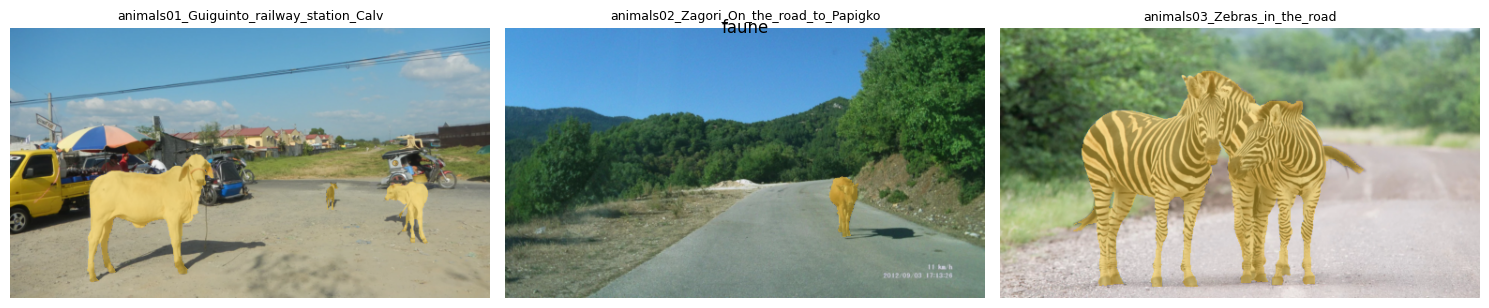

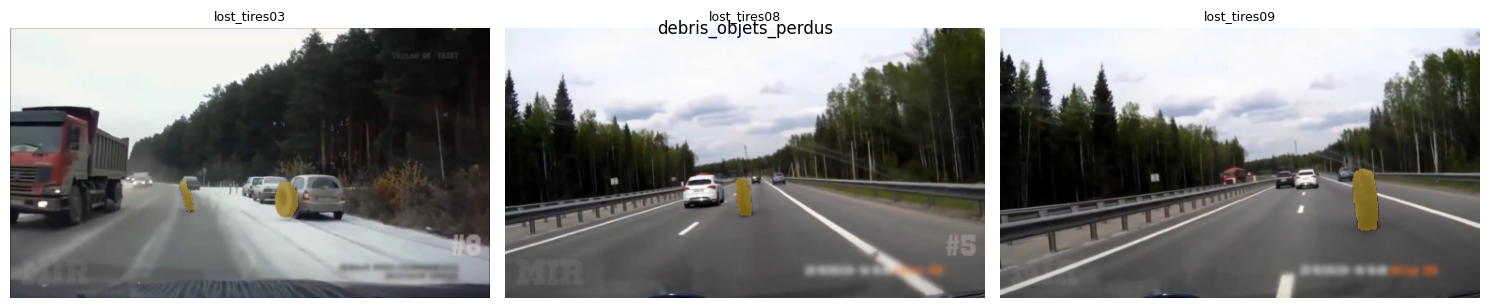

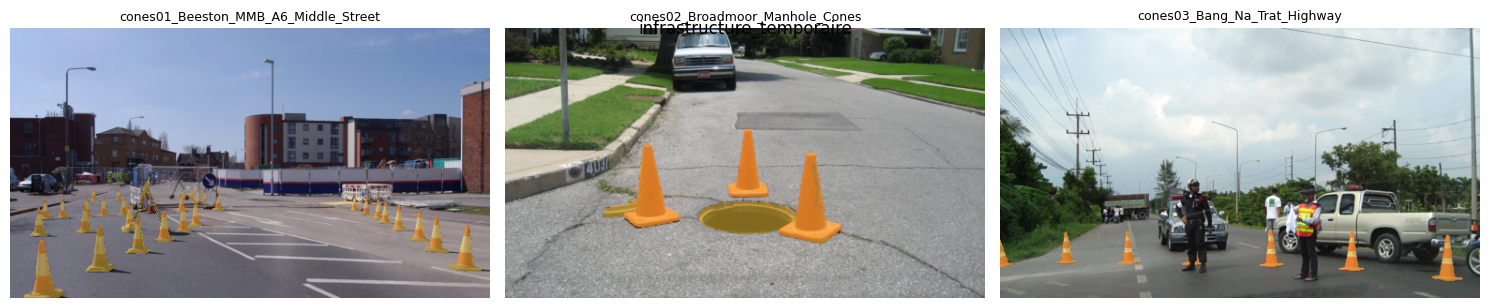

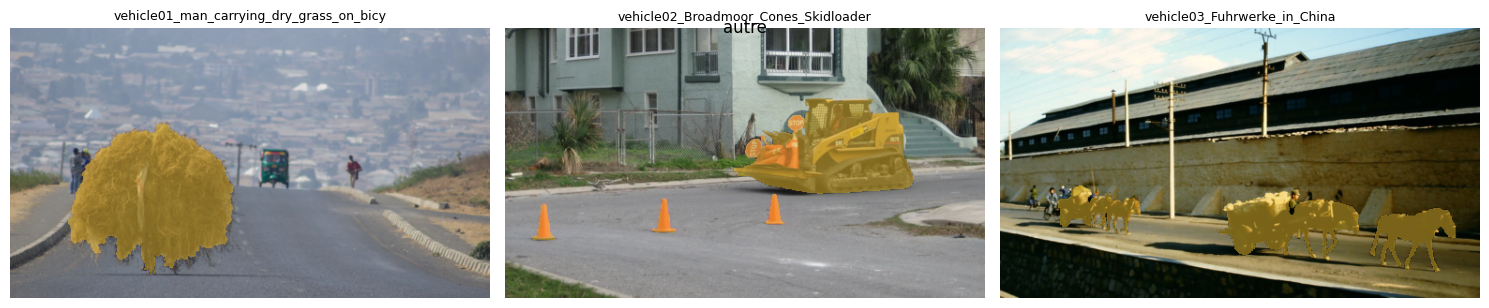

In [6]:
for fam in FAMILIES:
    sel = inv[inv.family == fam].name.tolist()[:3]
    if not sel:
        continue
    ims, ms = load_arrays(ROOT, sel, (W, H))
    show_samples(ims, ms, sel, n=len(sel), cols=3, path=os.path.join(FIG, f'01_samples_{fam}.png'))
    plt.suptitle(fam); plt.show()

## 4. Auditer les annotations

Contrôles automatiques sur chaque couple image / masque : image lisible, même taille que le masque,
valeurs attendues dans le masque (0 = fond, 2 = obstacle), présence d'au moins un pixel d'obstacle,
composantes minuscules (souvent du bruit d'annotation) et présence d'un masque d'instances.

In [7]:
audit = audit_annotations(ROOT, names)
audit.to_csv(os.path.join(RES, '01_audit_annotations.csv'), index=False)
flag = lambda c: audit[c].fillna(False).astype(bool)
checks = {
    'images_illisibles': int(audit.error.notna().sum()),
    'taille_image_differente_du_masque': int((~flag('size_match')).sum()),
    'valeurs_inattendues_dans_masque': int(flag('unexpected_values').sum()),
    'masques_sans_anomalie': int((audit.anomaly_fraction == 0).sum()),
    'images_avec_composantes_minuscules': int((audit.n_tiny_components > 0).sum()),
    'images_sans_masque_instance': int((~flag('has_instance_mask')).sum()),
}
display(pd.Series(checks, name='nombre d\'images'))
display(audit.groupby(['img_w', 'img_h']).size().rename('n_images'))
display(audit[['mask_values']].value_counts().rename('n_images'))

,nombre d'images
images_illisibles,0
taille_image_differente_du_masque,0
valeurs_inattendues_dans_masque,0
masques_sans_anomalie,0
images_avec_composantes_minuscules,18
images_sans_masque_instance,14


,,n_images
img_w,img_h,
1280,720,60


,n_images
mask_values,
"0,2",60


Les images qui contiennent des composantes minuscules sont affichées pour un contrôle visuel :

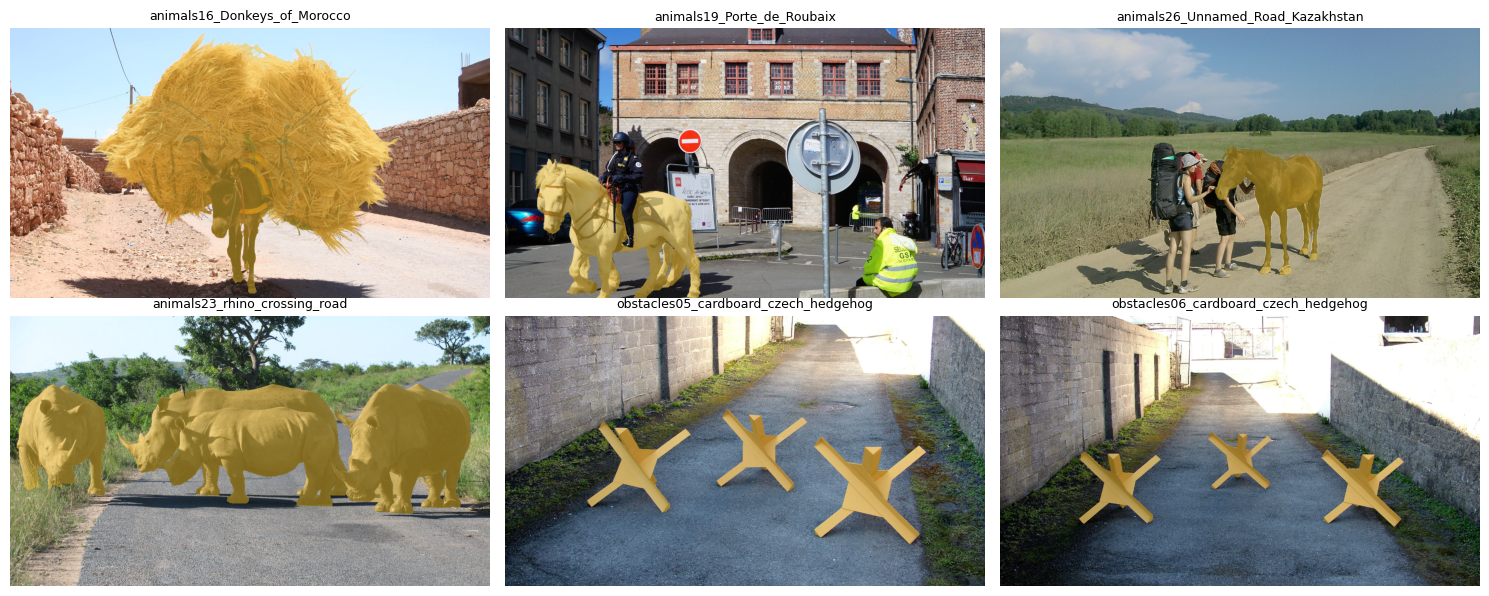

In [8]:
tiny = audit[audit.n_tiny_components > 0].sort_values('n_tiny_components', ascending=False).name.tolist()[:6]
if tiny:
    native = (int(audit.img_w.mode()[0]), int(audit.img_h.mode()[0]))   # résolution la plus fréquente
    ims, ms = load_arrays(ROOT, tiny, native)
    show_samples(ims, ms, tiny, n=len(tiny), path=os.path.join(FIG, '01_tiny_components.png')); plt.show()
else:
    print('Aucune composante minuscule détectée.')

## 5. Mesurer le déséquilibre et la taille des objets

Part des pixels d'obstacle par image (le fond domine largement) et surface de chaque objet à la
résolution de travail 512 × 288. Ces deux mesures guident les choix de la suite : perte pondérée,
métriques au pixel et par objet.

count    60.000000
mean      0.098496
std       0.100600
min       0.003747
25%       0.018016
50%       0.066229
75%       0.137958
max       0.423286
Name: anomaly_fraction, dtype: float64


,count,mean,median,min,max
family,,,,,
autre,3,0.102015,0.099709,0.076813,0.129524
debris_objets_perdus,13,0.073552,0.036287,0.003747,0.227217
faune,31,0.126714,0.081955,0.007992,0.423286
infrastructure_temporaire,13,0.055336,0.046476,0.010967,0.246829


size,grand,moyen,petit,All
family,,,,
autre,2,3,3,8
debris_objets_perdus,4,8,86,98
faune,17,25,108,150
infrastructure_temporaire,2,19,89,110
All,25,55,286,366


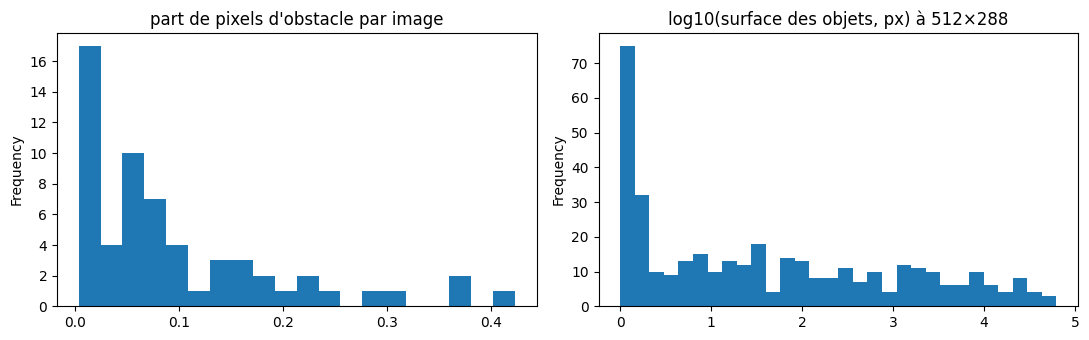

In [9]:
print(audit.anomaly_fraction.describe())
display(audit.groupby('family').anomaly_fraction.agg(['count', 'mean', 'median', 'min', 'max']))

ims, ms = load_arrays(ROOT, names, (W, H))
objs = object_sizes(ms, names)
objs['size'] = objs.area_px.map(size_bin)
objs.to_csv(os.path.join(RES, '01_objects.csv'), index=False)
display(pd.crosstab(objs.family, objs['size'], margins=True))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
audit.anomaly_fraction.plot.hist(bins=20, ax=ax[0], title="part de pixels d'obstacle par image")
np.log10(objs.area_px).plot.hist(bins=30, ax=ax[1], title=f'log10(surface des objets, px) à {W}×{H}')
fig.tight_layout(); fig.savefig(os.path.join(FIG, '01_imbalance_sizes.png'), dpi=150); plt.show()

## 6. Repérer les familles sous-représentées

Une famille qui représente moins de 15 % des images est jugée sous-représentée : ses résultats seront
peu fiables. Le fichier `01_criticite_template.csv` permet de noter la gravité de chaque famille.

In [10]:
UNDER_REP = 0.15
share = counts / counts.sum()
under = share[share < UNDER_REP]
print('Familles sous-représentées :', list(under.index))
crit = pd.DataFrame({'famille': FAMILIES, 'frequence_dataset': share.reindex(FAMILIES).values,
                     'criticite_expert_1a3': [None] * len(FAMILIES),
                     'justification': [''] * len(FAMILIES)})
crit.to_csv(os.path.join(RES, '01_criticite_template.csv'), index=False)
crit

Familles sous-représentées : ['autre']


,famille,frequence_dataset,criticite_expert_1a3,justification
0,faune,0.516667,None,
1,debris_objets_perdus,0.216667,None,
2,infrastructure_temporaire,0.216667,None,
3,autre,0.050000,None,


## 7. Définir les scénarios de sécurité

| Scénario | Familles | Risque principal | BO concernés |
|---|---|---|---|
| S1 Animal sur la voie du véhicule | faune | mouvement imprévisible, collision | BO1, BO2, BO3 |
| S2 Petit débris lointain | débris | détection tardive (objet de quelques pixels) | BO1, BO2 |
| S3 Cônes ou barrières qui réduisent la voie | infrastructure | mauvaise estimation de l'espace libre | BO2, BO3 |
| S4 Troupeau ou obstacle qui bloque la chaussée | faune, débris | voie bloquée, arrêt nécessaire | BO3 |

Le fichier `01_scenarios_template.csv` permet d'associer chaque image à un scénario.

In [11]:
scen = inv[['name', 'family']].assign(scenario='')
scen.to_csv(os.path.join(RES, '01_scenarios_template.csv'), index=False)

## 8. Sauvegarder le résumé

In [12]:
save_json({'notebook': '01', 'env': ENV, 'n_images': len(names),
           'images_par_famille': counts.to_dict(), 'controles_audit': checks,
           'objets_par_taille': objs['size'].value_counts().to_dict(),
           'familles_sous_representees': list(under.index)},
          os.path.join(RES, '01_exploration.json'))

## Conclusion (rédigée à partir des sorties ci-dessus, exécution du 05/11/2026)

- **60 images** : faune 31, débris / objets perdus 13, infrastructure temporaire 13, autre 3. La famille « autre » est sous-représentée.
- **Annotations saines** : aucune image illisible, aucune différence de taille image / masque, aucune valeur inattendue, aucun masque vide. 18 images contiennent des composantes minuscules (bruit d'annotation probable) et 14 n'ont pas de masque d'instances.
- **Objets surtout petits** : 286 petits, 55 moyens, 25 grands.
- **Conséquences** : perte pondérée contre le déséquilibre, découpage stratifié et groupé par scène, métriques au pixel et par objet, intervalles de confiance sur un test de 10 images.